<H1>Conjugate</H1> 
Analyze a problem from K1YBE. Question do the elements look the different when the S11 measurement is done
EG forward or backward. I think the real answer is that it is a S12 vs S21. Lets see what shakes out. 
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 27-Feb-26 </td>
        <td> CBL </td> 
        <td> Original </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
<a href = "https://scikit-rf.readthedocs.io/en/latest/tutorials/Circuit.html"> Example circuits </a><br> 
<a href = "https://onlinelibrary.wiley.com/doi/10.1002/mop.10983"> Microwave S-Parameter reduction </a><br>
<a href = "https://scikit-rf.readthedocs.io/en/latest/tutorials/Media.html"> RG58 example </a><br>
<a href = "https://scikit-rf.readthedocs.io/en/latest/api/media/generated/skrf.media.coaxial.Coaxial.html"> Coaxial </a><br>

<H2> Notes </H2>
Originated with Bruce Manning, NJ3K

In [1]:
# imports - package libraries etc. 
import numpy as np
import matplotlib.pyplot as plt
import math
import skrf as rf
from skrf.media import Coaxial
from timeit import timeit
from skrf import Network
from skrf import Frequency
from skrf.circuit import Circuit
from skrf.tlineFunctions import INF
#
# skrf figure styling
rf.stylely()

In [2]:
# Create a coaxial cable 
# https://scikit-rf.readthedocs.io/en/latest/api/media/generated/skrf.media.coaxial.Coaxial.html
# coaxial properties:
#
# https://www.everythingrf.com/tech-resources/rf-cable-specifications
#
# frequency, Bruce's notes is {7.841, 23.164, 69.2} MHz
#
f_rg8 = rf.Frequency(7, 70, 101, 'MHz')

# media with z0_port the port impedance of the VNA
"""
Arguments: 
  frequency (Frequency object) – Frequency band.
  z0_port (number, array-like, or None) – z0_port is the port impedance for networks generated by the media. If z0_port is not None, the networks generated by the media are renormalized (or in other words embedded) from the characteristic impedance z0 of the media to z0_port. Else if z0_port is None, the networks port impedances will be the raw characteristic impedance z0 of the media. (Default is None)
  z0_override (number, array-like, or None) – z0_override override the characteristic impedance for the media. If z0_override is not None, the networks generated by the media have their characteristic impedance z0 overrided by z0_override. (Default is None)
  z0 (number, array-like, or None) – deprecated parameter, alias to z0_override if z0_override is None. Emmit a deprecation warning.
  Dint (number, or array-like) – inner conductor diameter, in m
  Dout (number, or array-like) – outer conductor diameter, in m
  epsilon_r (number, or array-like, optional) – relative permittivity of the dielectric medium. Default is 1.
  tan_delta (number, or array-like, optional) – loss tangent of the dielectric medium. Default is 0.
  sigma (number, or array-like, optional.) – conductors electrical conductivity, in S/m. Default is infinity (non lossy metal).

  coaxial properties:
  https://www.everythingrf.com/tech-resources/rf-cable-specifications
  Model RG8X
  Dielectric is FPE - Time Delay: 1.27s/ft, Propigation Velocity: 0.80
  Capacitance per foot: ~25pF/ft
  Center conductor is 16AWG, Diameter is 0.0508 inches/1.29mm
  Dielectric diameter: 0.155 inches, 3.94mm
  e_r = 2.3
"""
#rg8 = Coaxial(f_rg8, Dint = 1.29e-3, Dout = 3.94e-3, epsilon_r = 1.9, z0_port = 50)
# I fiddled with the parameters to get as close as possible to the impedance. 
rg8 = Coaxial(f_rg8, Dint = 1.2e-3, Dout = 3.94e-3, epsilon_r = 2.0, z0_port = 50)
print(rg8)

Coaxial Media.  Coaxial Media.  7.0-70.0MHz, 101 points.
Dint = 1.20 mm, Dout = 3.94 mm
z0 = (50.4, -0.0j)-(50.4, -0.0j) Ohm
z0_port = (50.0, 0.0j)-(50.0, 0.0j) Ohm



Text(0, 0.5, 'Characteristic Impedance (ohms)')

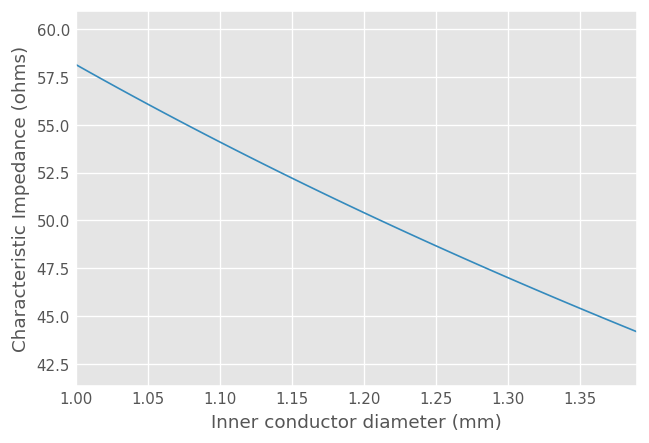

In [3]:
# Lets briefly look at the sensitivity of the system.
# First vary the inner diameter
D_inner = np.arange(1.0, 1.4, 0.01) * 1.0e-3
y = np.zeros(40)
i = 0
for D in D_inner:
    rg8_p = Coaxial(f_rg8, Dint = D, Dout = 3.94e-3, epsilon_r = 2.0, z0_port = 50)
    y[i] = rg8_p.z0[0].real
    i = i+1
plt.plot(D_inner*1.0e3,y)
#rg8_p.z0[0].real
plt.xlabel("Inner conductor diameter (mm)")
plt.ylabel("Characteristic Impedance (ohms)")

Text(0, 0.5, 'Characteristic Impedance (ohms)')

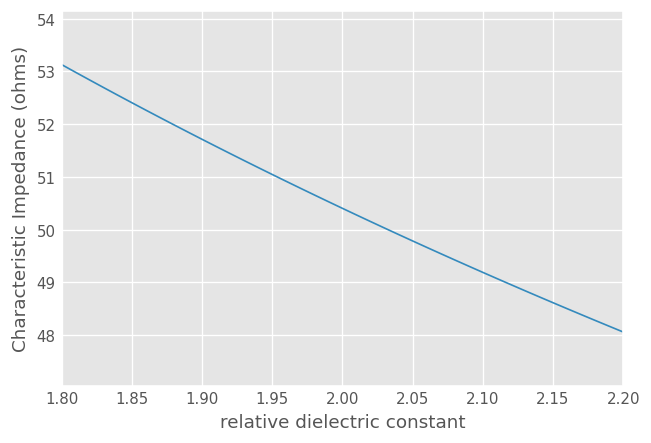

In [4]:
# and the same for the dielectric
ex = np.arange(1.8, 2.2, 0.01)
y = np.zeros(len(ex))
i = 0
for e in ex:
    rg8_p = Coaxial(f_rg8, Dint = 1.2e-3, Dout = 3.94e-3, epsilon_r = e, z0_port = 50)
    y[i] = rg8_p.z0[0].real
    i = i+1
plt.plot(ex,y)
plt.xlabel("relative dielectric constant")
plt.ylabel("Characteristic Impedance (ohms)")

That allows us to examine the properties of the coaxial cable. But we really want to know how the network
actually works. Lets make the individual elements then assemble them into a circuit and apply measurements. 

In [5]:
# Setup a frequency array, Use the same values as Paul
#
f = np.array([7.841, 23.164, 69.2]) # in MHz
# Before creating the scikit-rf Network object, one must forge the Frequency and S-matrix:
freq = rf.Frequency.from_f(f, unit='MHz')


There are a lot of incomplete thoughts here

In [2]:
# https://scikit-rf.readthedocs.io/en/v1.8.0/examples/circuit/Lumped%20Element%20Circuits.html
# The example imports from an ansys designer tool. let do it manually
# Define my components here. 
# Frequency domain
scan_frequency = rf.Frequency(7.0, 64.0, 101, 'mhz')
# create a resistor
# https://scikit-rf.readthedocs.io/en/latest/api/generated/skrf.circuit.Circuit.SeriesImpedance.html
R0 = Circuit.SeriesImpedance(scan_frequency, INF, name='R0', z0=50.0)
#
R_val = 75.0 # ohms
R1 = Circuit.SeriesImpedance(scan_frequency, INF , name ='R1', z0=R_val)  # real ohms
# Create inductor too. 
XL = 71.3j
#Z  = np.zeros(len(scan_frequency),dtype=complex)
# Z was rf.INF
L1 = Circuit.SeriesImpedance(scan_frequency, INF, name = 'L1', z0=XL * 2 * np.pi * scan_frequency.f * 1e-9) # 71.3 nH inductor
# Capacitor not used, here as placeholder
# https://scikit-rf.readthedocs.io/en/latest/api/generated/skrf.circuit.Circuit.ShuntAdmittance.html
C1 = Circuit.ShuntAdmittance(scan_frequency, INF, name = 'C1', z0=1j * 2 * np.pi * scan_frequency.f * 1e-12) # 1 pF shunt capacitor
#
# What does it mean to design a port? 
# https://scikit-rf.readthedocs.io/en/v1.8.0/api/generated/skrf.circuit.Circuit.Port.html
#
port1  = Circuit.Port(frequency=scan_frequency, name='P1', z0=50)
port2  = Circuit.Port(frequency=scan_frequency, name='P2', z0=50)
ground = Circuit.Ground(scan_frequency, name='ground')

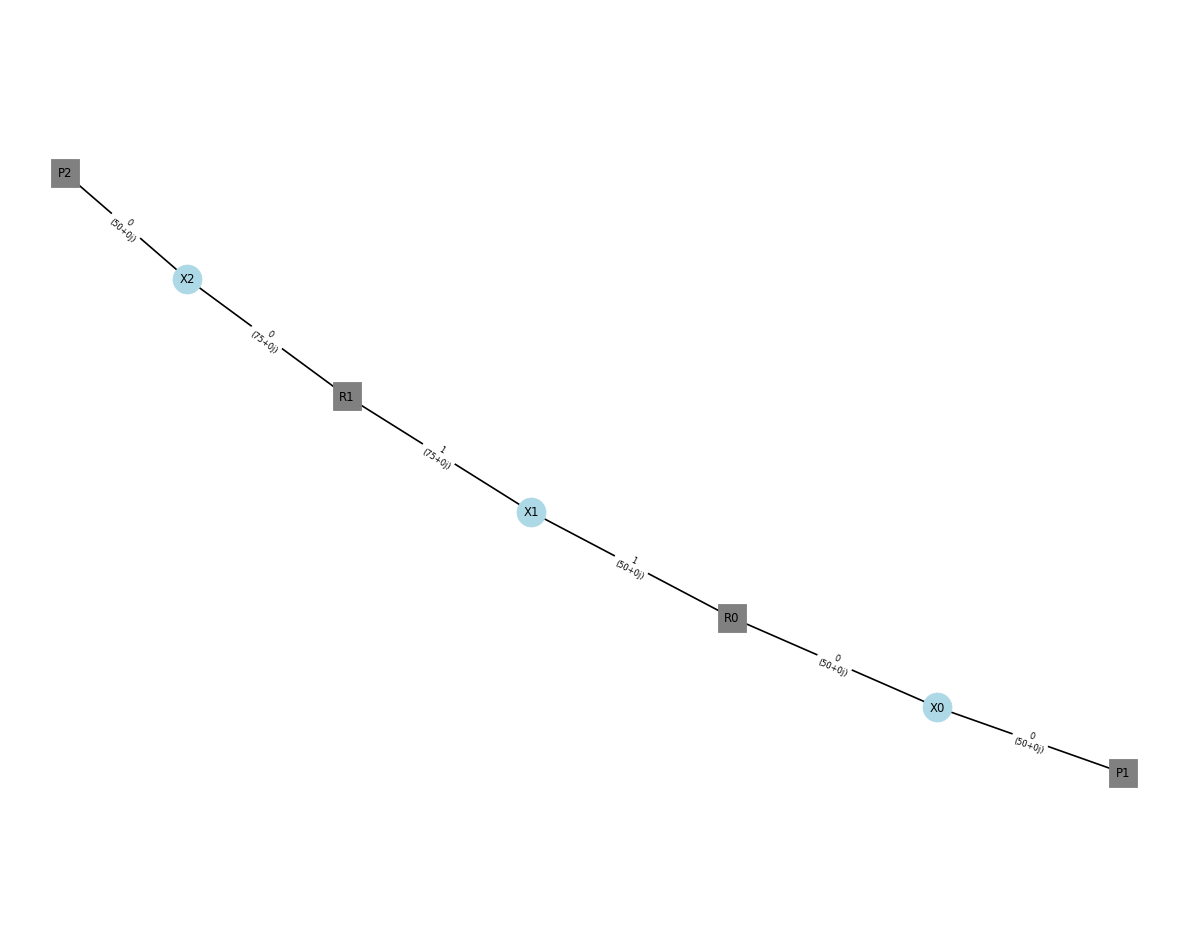

In [3]:
# Make a simple ciruit of a resistor only
#simple circuit
Rconnections = [
    [(port1, 0), (R0, 0)],
    [(R0, 1), (R1, 1)],
    [(R1, 0), (port2, 0)]
]
Rcircuit = Circuit(Rconnections)
Rcircuit.plot_graph(network_labels=True,edge_labels=True,port_labels=True,inter_labels=True)

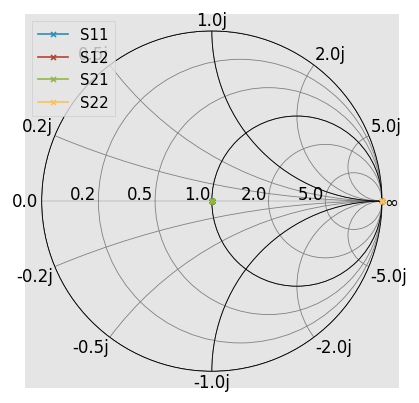

In [4]:
# show the smith chart for the above. 
# https://scikit-rf.readthedocs.io/en/latest/api/generated/skrf.network.Network.plot_s_smith.html
Rcircuit.network.plot_s_smith(draw_labels=True,marker='x')

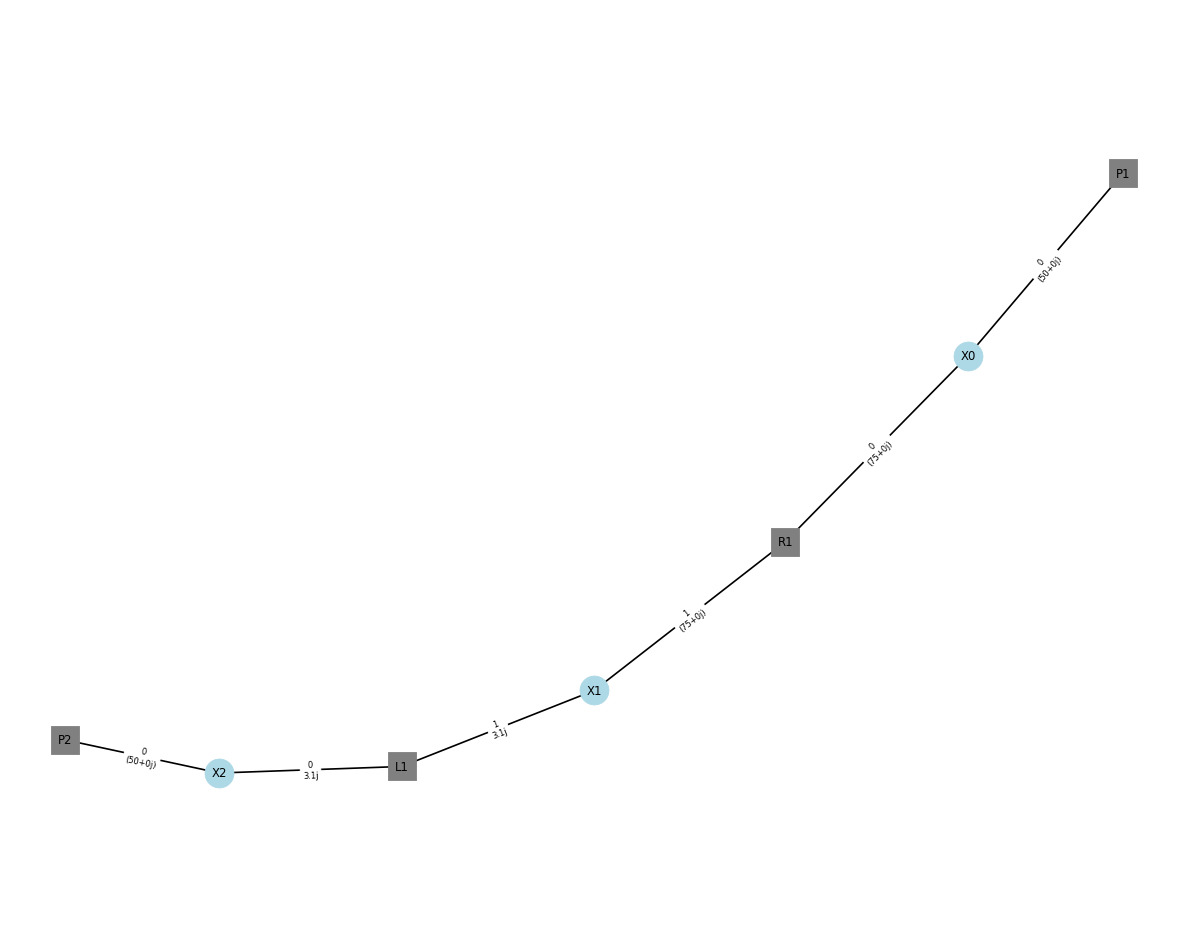

In [5]:
# more complex circuit
connections = [
    [(port1, 0), (R1, 0)],
    [(R1, 1), (L1,1)],
    [(L1, 0), (port2, 0)]
]
circuit = Circuit(connections)
#LC_from_circuit = circuit.network
#
# Draw the resulting graph
#
circuit.plot_graph(network_labels=True,edge_labels=True,port_labels=True,inter_labels=True)

/Users/christopherlirakis/.envJupyter/lib/python3.13/site-packages/skrf/network.py:6974: RuntimeWarning: divide by zero encountered in divide
  np.einsum('ijj->ij', F)[...] = 1.0/(np.sqrt(z0.real))
/Users/christopherlirakis/.envJupyter/lib/python3.13/site-packages/skrf/network.py:7018: RuntimeWarning: invalid value encountered in divide
  s_new[:, m, n] = b[:, m, n] / a[:, n, n]


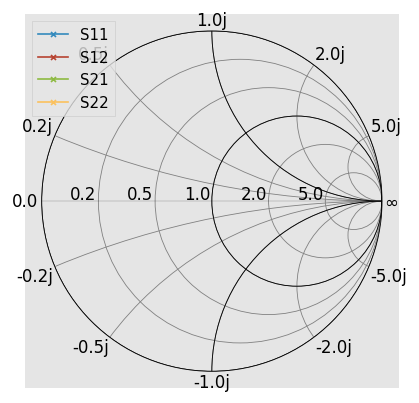

In [4]:
# show the smith chart for the above. 
# https://scikit-rf.readthedocs.io/en/latest/api/generated/skrf.network.Network.plot_s_smith.html
circuit.network.plot_s_smith(draw_labels=True,marker='x')

In [9]:
LC_from_circuit.s[:11,0,1]

array([nan+nanj, nan+nanj, nan+nanj, nan+nanj, nan+nanj, nan+nanj,
       nan+nanj, nan+nanj, nan+nanj, nan+nanj, nan+nanj])

So why is there zeros in the circuit, do I have to add a finite resistance to the inductor??

In [7]:
# define new inductor
# Create inductor too. 
RL = 1.0e-3
ZL  = np.ones(len(scan_frequency),dtype=complex) * RL
XL = 71.3j * 2 * np.pi * scan_frequency.f * 1e-9
ZL = ZL + XL
Z0_2 = XL * 2 * np.pi * scan_frequency.f * 1e-9

L2 = Circuit.SeriesImpedance(scan_frequency, INF, name = 'L1', z0=Z0_2) # 71.3 nH inductor with finite resistance


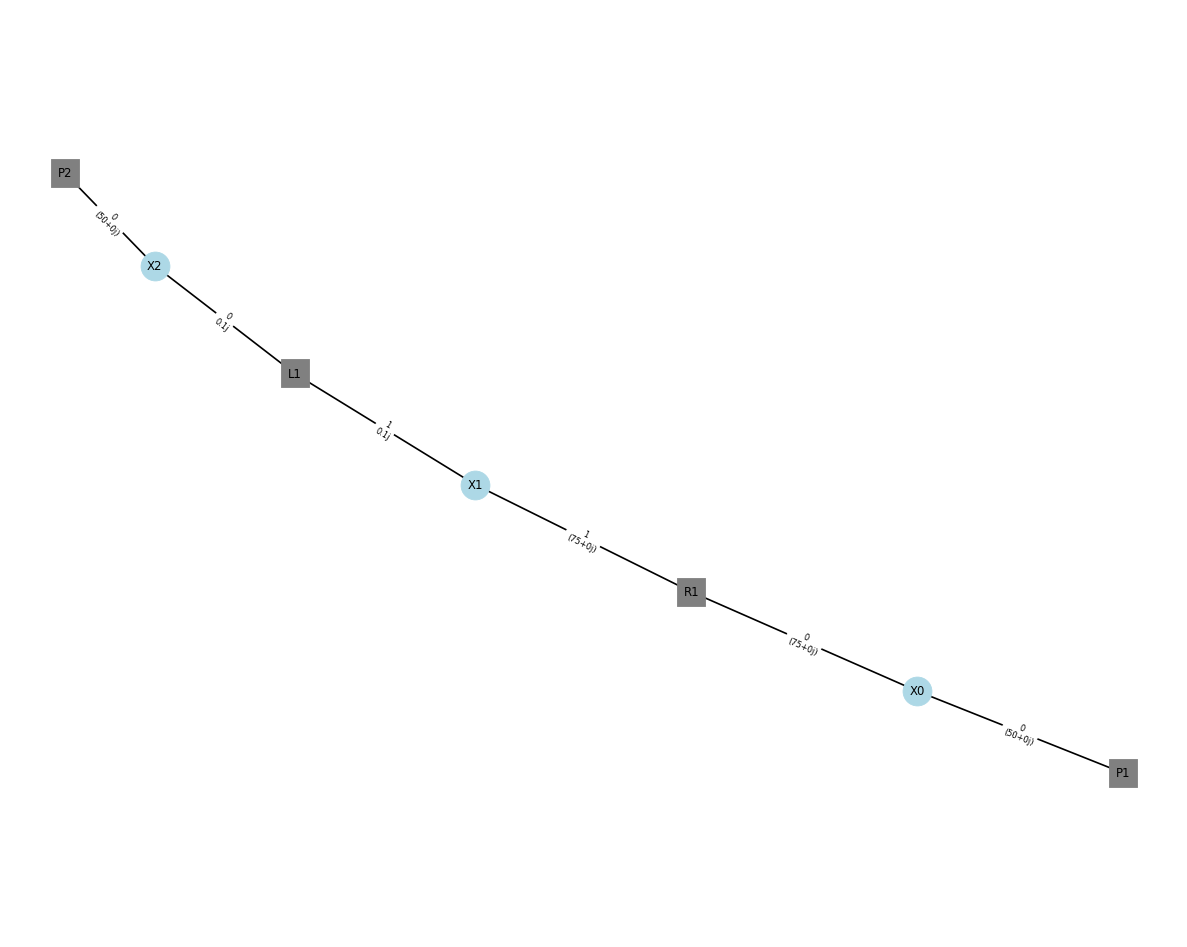

In [9]:
# more complex circuit
connections2 = [
    [(port1, 0), (R1, 0)],
    [(R1, 1), (L2,1)],
    [(L2, 0), (port2, 0)]
]
circuit2 = Circuit(connections2)
#
# Draw the resulting graph
#
circuit2.plot_graph(network_labels=True,edge_labels=True,port_labels=True,inter_labels=True)